# Teacher: run every group case (backup)

**Not for students.** Keep this on the `solutions` branch.

The cases of `GROUP_TASKS.md`, run with the same steps as `Base_case.ipynb` (same wrapper, template and defaults). Each case is run in `cases/<name>/`, and its small `results.nc` is copied to `backup_results/<name>/` (to commit; the SWASH files in `cases/` are too big).

Use it to check before class that SWASH works and how long a case takes, to have every group's result ready if something fails in class, and to feed `Conclusions.ipynb`.

Cases already in `backup_results/` are skipped, so you can stop and restart.

In [8]:
import os
import os.path as op
import shutil
import time

import numpy as np
import pandas as pd
import xarray as xr

from scripts.wrappers import SwashModelWrapper_ondas
from scripts.bathymetry import linear_profile, reef_profile
from scripts.results import save_case, case_table, plot_results, trend_table

templates_dir = op.join(os.getcwd(), 'templates', 'templates_test')
output_dir = op.join(os.getcwd(), 'cases')
backup_dir = op.join(os.getcwd(), 'backup_results')

## The steps of Base_case.ipynb, as one function

`DEFAULTS` are the values the student notebook starts with. A case is the defaults plus what the group changes.

In [9]:
DEFAULTS = dict(WAVE="jonswap", Hs=2.5, Tp=10, WL=0.0, GAMMA=3.3,
                PROFILE="beach", h0=-12, m=1/30, bar_height=0, bar_x=650,
                reef_depth=2.5, reef_width=200, MANNING_N=0.01)


def build_profile(c):
    # Same as the "Create bathymetry" cells
    if c["PROFILE"] == "beach":
        x_profile, depth_array = linear_profile(h0=c["h0"], Ltotal=1000, Wconst=400, slope=c["m"])
        depth_array = depth_array + c["bar_height"] * np.exp(-((x_profile - c["bar_x"]) / 40) ** 2)
    else:
        x_profile, depth_array = reef_profile(dx=1, h0=15, Slope1=0.05, Slope2=0.1,
                                              Wreef=c["reef_width"], Wfore=500, bCrest=10,
                                              emsl=c["reef_depth"])
    return np.arange(len(depth_array)), np.asarray(depth_array, float)


def run_case(CASE_NAME, comptime=900, warmup=300, keep=True, **changes):
    c = {**DEFAULTS, **changes}
    x_profile, depth_array = build_profile(c)
    Hs_L0 = (2 * np.pi * c["Hs"]) / (9.81 * c["Tp"] ** 2)

    metamodel_parameters = pd.DataFrame({
        'Hs': c["Hs"], 'Hs_L0': Hs_L0, 'WL': c["WL"], 'wave_type': c["WAVE"],
        'jonswap_gamma': c["GAMMA"], 'manning_n': c["MANNING_N"],
    }, index=[0]).to_dict(orient='list')
    fixed_parameters = {"dxinp": 1, "comptime": comptime, "warmup": warmup,
                        "n_nodes_per_wavelength": 60}

    swash_model = SwashModelWrapper_ondas(
        templates_dir=templates_dir,
        metamodel_parameters=metamodel_parameters,
        fixed_parameters=fixed_parameters,
        output_dir=output_dir,
        depth_array=-depth_array,
    )
    swash_model.build_cases(cases_name_format=lambda ctx: CASE_NAME)
    swash_model.run_cases(launcher='serial')

    postprocessed = swash_model.postprocess_cases(
        output_vars=["Msetup", "Hrms", "Hfreqs", "Ru2"]).isel(case_num=0)
    with xr.open_dataset(op.join(output_dir, CASE_NAME, 'output.nc')) as output_data:
        output_data = output_data.load()
    if np.isnan(output_data["Watlev"].values).any():
        print(f"WARNING {CASE_NAME}: NaN in the water level, the model became unstable")
    save_case(CASE_NAME, postprocessed, x_profile, depth_array, c["WL"], c["Hs"], c["Tp"],
              c["WAVE"], output_dir, c["MANNING_N"], output_data)
    if keep:
        os.makedirs(op.join(backup_dir, CASE_NAME), exist_ok=True)
        shutil.copy(op.join(output_dir, CASE_NAME, 'results.nc'),
                    op.join(backup_dir, CASE_NAME, 'results.nc'))

## 1. Quick check: does SWASH run, and how long does a case take?

Four short runs (60 s warmup + 120 s): regular and JONSWAP, on the beach and on the reef. Not kept.
A full case is 1200 s of sea, so roughly **7×** the time printed.

In [10]:
for profile in ("beach", "reef"):
    for wave in ("mono", "jonswap"):
        start = time.time()
        run_case(f"smoke_{profile}_{wave}", comptime=120, warmup=60, keep=False,
                 PROFILE=profile, WAVE=wave)
        minutes = (time.time() - start) / 60
        print(f"   {profile} {wave}: {minutes:.1f} min -> a full case is about {7 * minutes:.0f} min\n")

2026-11-09 13:14:51,433 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 13:14:51,435 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 13:14:51,436 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters
2026-11-09 13:15:01,309 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 13:15:01,311 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 13:15:01,312 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters


Saved as 'smoke_beach_mono'. Ru2 = 1.18 m
   beach mono: 0.2 min -> a full case is about 1 min



2026-11-09 13:15:10,786 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 13:15:10,787 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 13:15:10,788 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters


Saved as 'smoke_beach_jonswap'. Ru2 = 1.17 m
   beach jonswap: 0.2 min -> a full case is about 1 min



2026-11-09 13:15:22,374 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 13:15:22,375 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 13:15:22,375 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters


Saved as 'smoke_reef_mono'. Ru2 = 1.58 m
   reef mono: 0.2 min -> a full case is about 1 min

Saved as 'smoke_reef_jonswap'. Ru2 = 1.38 m
   reef jonswap: 0.2 min -> a full case is about 1 min



## 2. The group cases

The same names and values as `GROUP_TASKS.md`.

In [11]:
GROUPS = {
    "A: irregular instead of regular": {"A_mono": dict(WAVE="mono"),
                                        "A_jonswap": dict(WAVE="jonswap")},
    "B: Hs":                           {"B_Hs1": dict(Hs=1.0), "B_Hs2_5": dict(Hs=2.5),
                                        "B_Hs4": dict(Hs=4.0)},
    "C: Tp":                           {"C_Tp7": dict(Tp=7.0), "C_Tp10": dict(Tp=10.0),
                                        "C_Tp14": dict(Tp=14.0)},
    "D: beach slope":                  {"D_m30": dict(m=1/30), "D_m20": dict(m=1/20),
                                        "D_m15": dict(m=1/15)},
    "E: bar height":                   {"E_nobar": dict(bar_height=0.0),
                                        "E_bar1_5": dict(bar_height=1.5),
                                        "E_bar2_5": dict(bar_height=2.5)},
    "F: water level on the reef":      {"F_WLm1": dict(PROFILE="reef", WL=-1.0),
                                        "F_WL0": dict(PROFILE="reef", WL=0.0),
                                        "F_WLp1": dict(PROFILE="reef", WL=1.0)},
    "G: Gamma":                        {"G_gamma1": dict(GAMMA=1), 
                                        "G_gamma3_3": dict(GAMMA=3.3), 
                                        "G_gamma7": dict(GAMMA=7)},
    "Extra: reef roughness":           {"X_n001": dict(PROFILE="reef", MANNING_N=0.01),
                                        "X_n01": dict(PROFILE="reef", MANNING_N=0.1),
                                        "X_n02": dict(PROFILE="reef", MANNING_N=0.2)},
}
print(sum(len(g) for g in GROUPS.values()), "cases")

23 cases


## 3. Run them all

The long step. A case that fails is reported and the loop carries on.

In [12]:
failed = {}
for group, cases in GROUPS.items():
    for name, changes in cases.items():
        if op.exists(op.join(backup_dir, name, 'results.nc')):
            print(f"{name}: already done, skipped")
            continue
        print(f"=== {name}  {changes}")
        start = time.time()
        try:
            run_case(name, **changes)
            print(f"   {(time.time() - start) / 60:.1f} min")
        except Exception as error:
            failed[name] = error
            print(f"   FAILED: {error}")

print("\nFailed:", failed or "none")

2026-11-09 13:15:34,138 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 13:15:34,139 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 13:15:34,140 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters


A_mono: already done, skipped
A_jonswap: already done, skipped
B_Hs1: already done, skipped
B_Hs2_5: already done, skipped
B_Hs4: already done, skipped
C_Tp7: already done, skipped
C_Tp10: already done, skipped
C_Tp14: already done, skipped
D_m30: already done, skipped
D_m20: already done, skipped
D_m15: already done, skipped
E_nobar: already done, skipped
E_bar1_5: already done, skipped
E_bar2_5: already done, skipped
F_WLm1: already done, skipped
F_WL0: already done, skipped
F_WLp1: already done, skipped
=== G_gamma1  {'GAMMA': 1}


2026-11-09 13:16:51,017 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 13:16:51,017 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 13:16:51,018 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters


Saved as 'G_gamma1'. Ru2 = 1.47 m
   1.3 min
=== G_gamma3_3  {'GAMMA': 3.3}


2026-11-09 13:18:03,276 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 13:18:03,277 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 13:18:03,278 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters


Saved as 'G_gamma3_3'. Ru2 = 1.41 m
   1.2 min
=== G_gamma7  {'GAMMA': 7}
Saved as 'G_gamma7'. Ru2 = 1.36 m
   1.2 min
X_n001: already done, skipped
X_n01: already done, skipped
X_n02: already done, skipped

Failed: none


If a case failed or printed `WARNING ... unstable`: delete its folder in `backup_results/`, change its value slightly here **and** in `GROUP_TASKS.md`, and run step 3 again.

## 4. Check each group

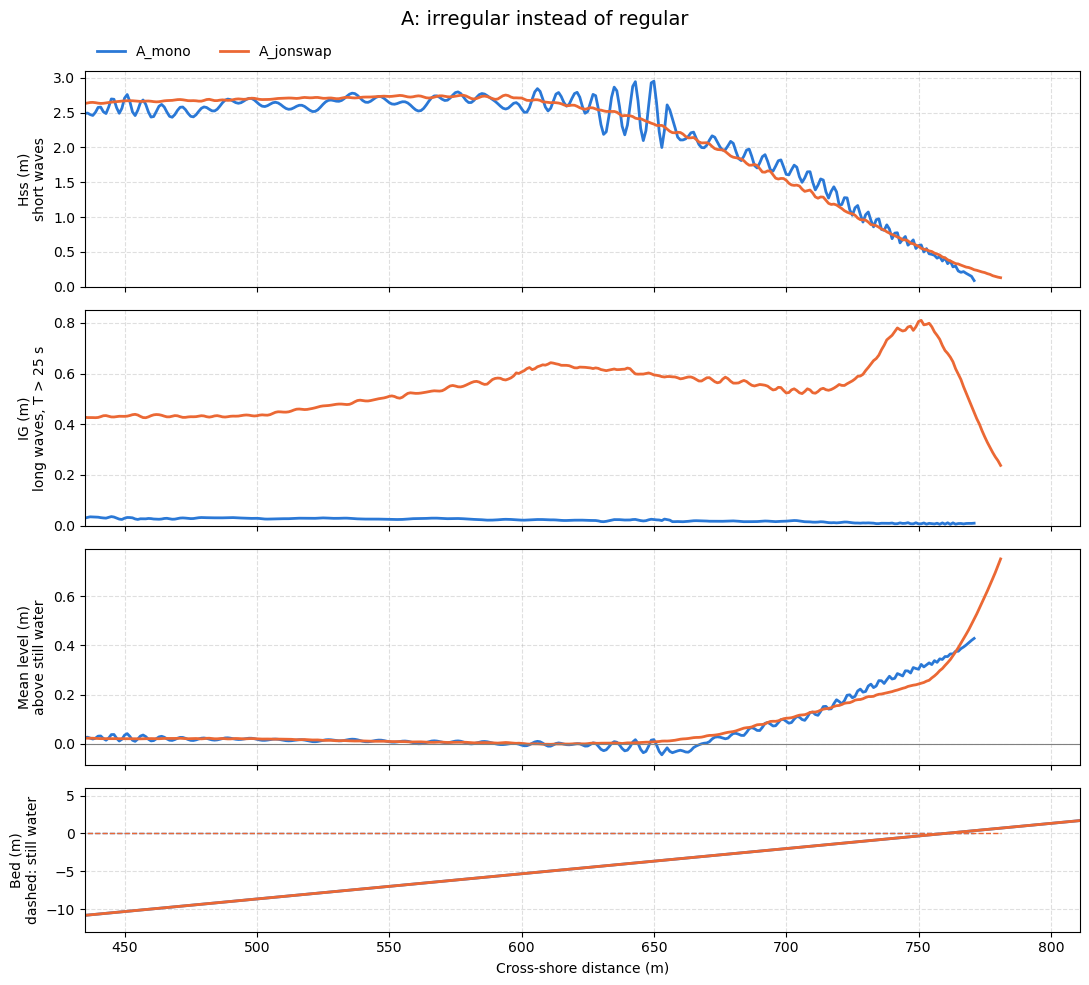

,A_mono,A_jonswap
wave,mono,jonswap
Hs (m),2.5,2.5
Tp (s),10.0,10.0
WL (m),0.0,0.0
Manning n,0.01,0.01
x_break (m),650.0,638.0
Hss/h at break,0.66,0.6
"Hss, h=1 m (m)",0.89,0.81
"IG, h=1 m (m)",0.01,0.71
IG/Hss,0.01,0.87


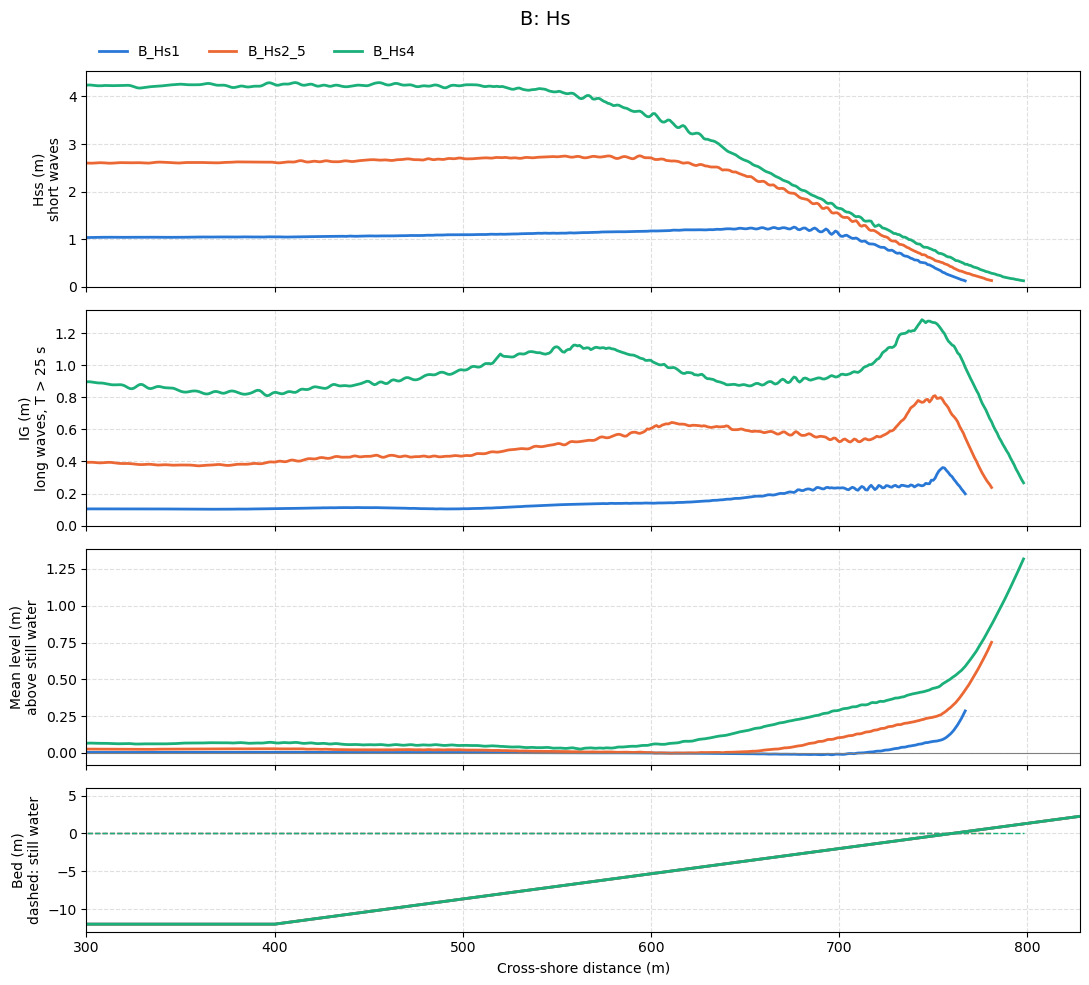

,B_Hs1,B_Hs2_5,B_Hs4
wave,jonswap,jonswap,jonswap
Hs (m),1.0,2.5,4.0
Tp (s),10.0,10.0,10.0
WL (m),0.0,0.0,0.0
Manning n,0.01,0.01,0.01
x_break (m),698.0,638.0,580.0
Hss/h at break,0.54,0.6,0.64
"Hss, h=1 m (m)",0.7,0.81,0.89
"IG, h=1 m (m)",0.24,0.71,1.27
IG/Hss,0.35,0.87,1.42


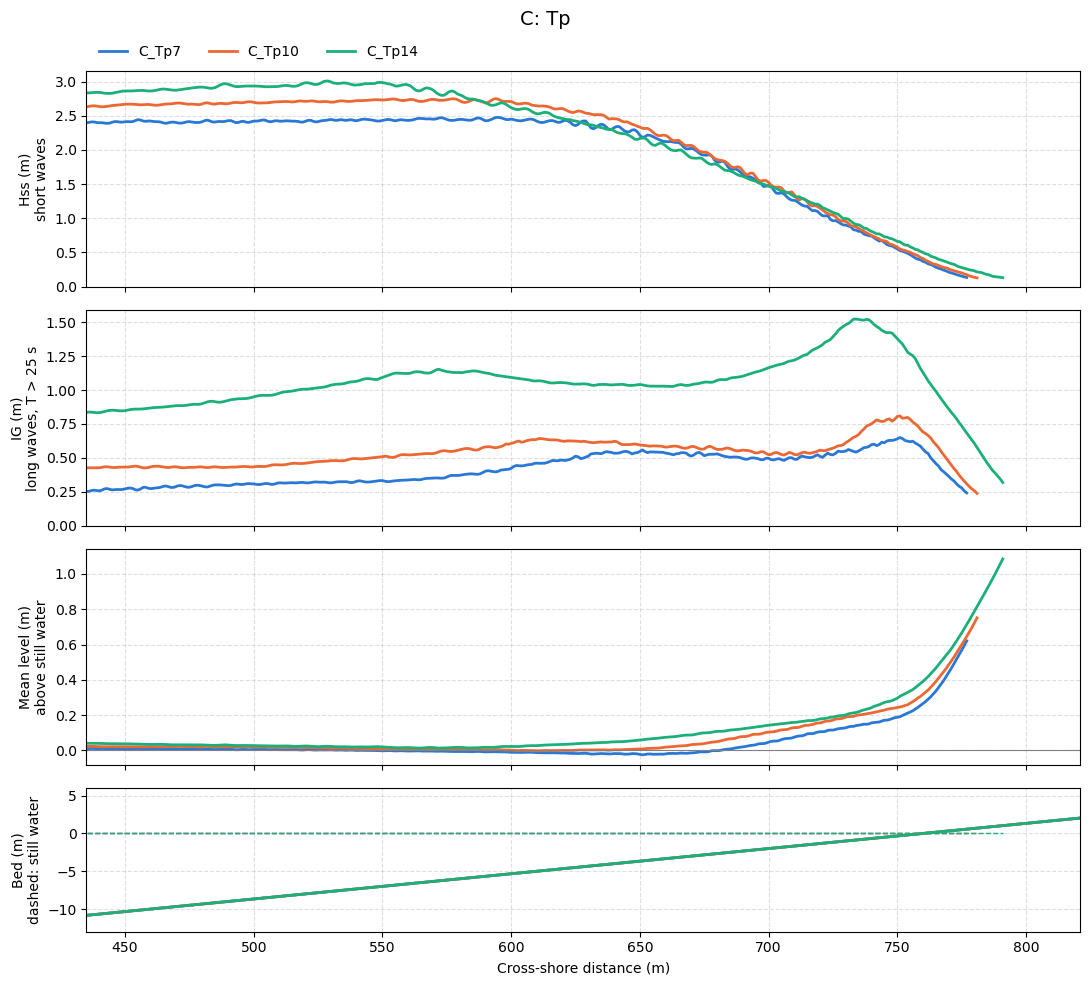

,C_Tp7,C_Tp10,C_Tp14
wave,jonswap,jonswap,jonswap
Hs (m),2.5,2.5,2.5
Tp (s),7.0,10.0,14.0
WL (m),0.0,0.0,0.0
Manning n,0.01,0.01,0.01
x_break (m),652.0,638.0,593.0
Hss/h at break,0.62,0.6,0.48
"Hss, h=1 m (m)",0.81,0.81,0.86
"IG, h=1 m (m)",0.55,0.71,1.52
IG/Hss,0.68,0.87,1.77


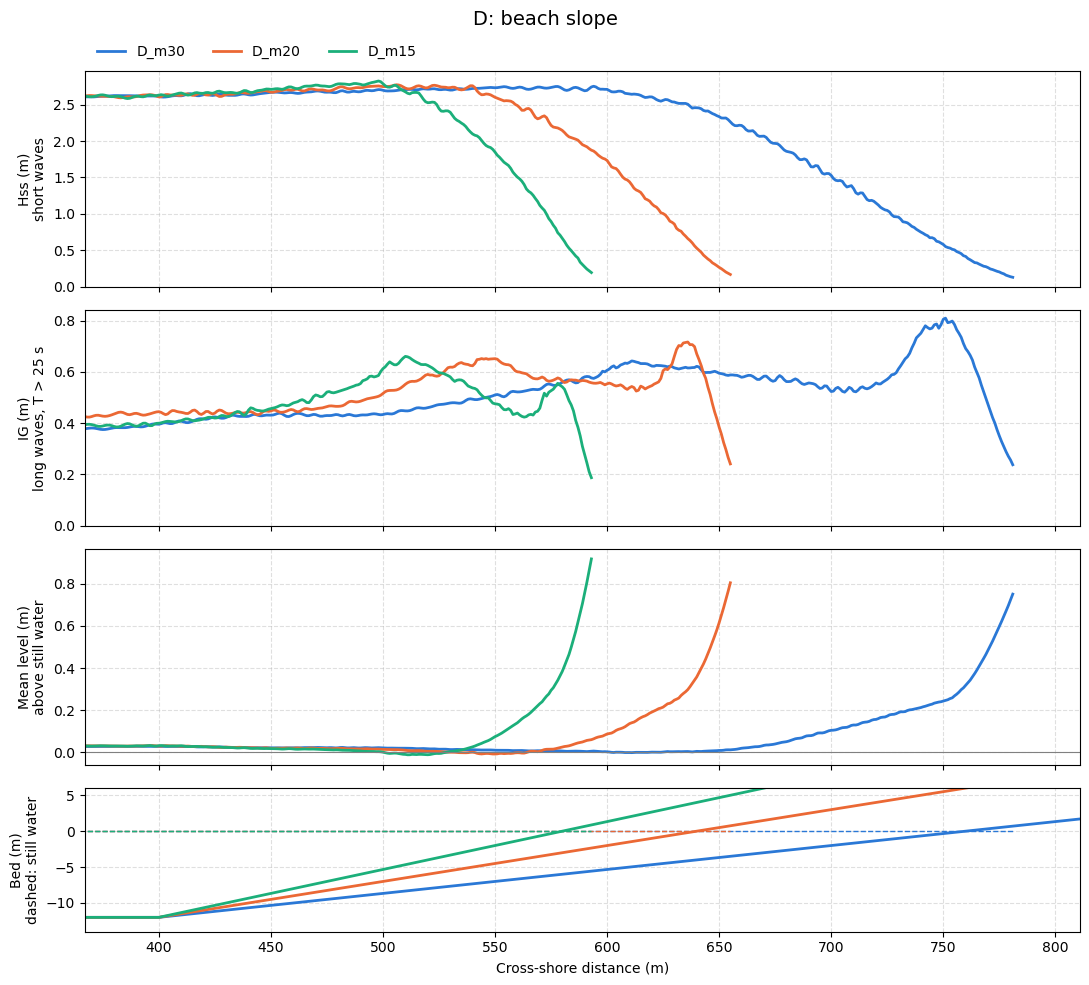

,D_m30,D_m20,D_m15
wave,jonswap,jonswap,jonswap
Hs (m),2.5,2.5,2.5
Tp (s),10.0,10.0,10.0
WL (m),0.0,0.0,0.0
Manning n,0.01,0.01,0.01
x_break (m),638.0,559.0,521.0
Hss/h at break,0.6,0.61,0.64
"Hss, h=1 m (m)",0.81,1.0,1.17
"IG, h=1 m (m)",0.71,0.61,0.45
IG/Hss,0.87,0.6,0.38


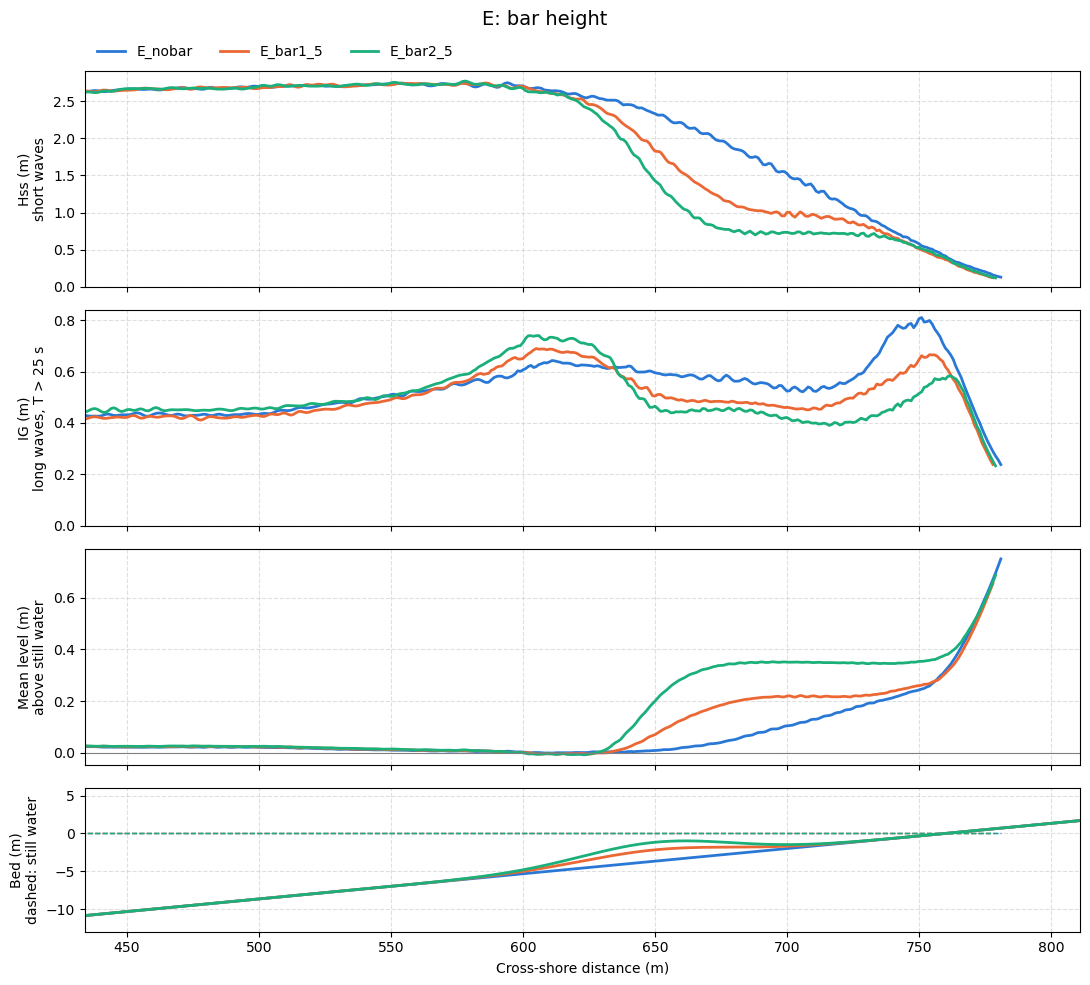

,E_nobar,E_bar1_5,E_bar2_5
wave,jonswap,jonswap,jonswap
Hs (m),2.5,2.5,2.5
Tp (s),10.0,10.0,10.0
WL (m),0.0,0.0,0.0
Manning n,0.01,0.01,0.01
x_break (m),638.0,623.0,619.0
Hss/h at break,0.6,0.68,0.74
"Hss, h=1 m (m)",0.81,0.71,0.65
"IG, h=1 m (m)",0.71,0.56,0.45
IG/Hss,0.87,0.79,0.69


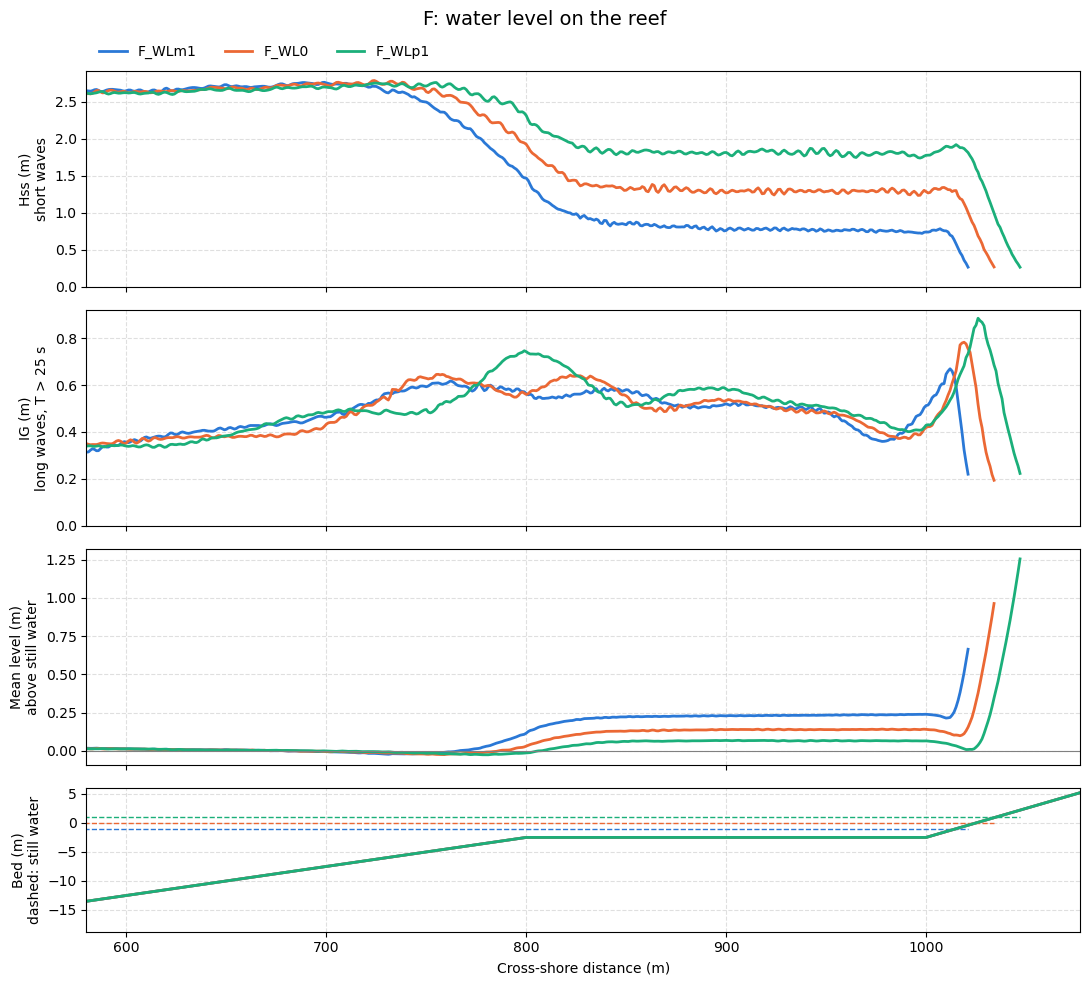

,F_WLm1,F_WL0,F_WLp1
wave,jonswap,jonswap,jonswap
Hs (m),2.5,2.5,2.5
Tp (s),10.0,10.0,10.0
WL (m),-1.0,0.0,1.0
Manning n,0.01,0.01,0.01
x_break (m),749.0,767.0,788.0
Hss/h at break,0.61,0.6,0.61
"Hss, h=1 m (m)",0.77,1.19,1.55
"IG, h=1 m (m)",0.61,0.77,0.89
IG/Hss,0.79,0.65,0.57


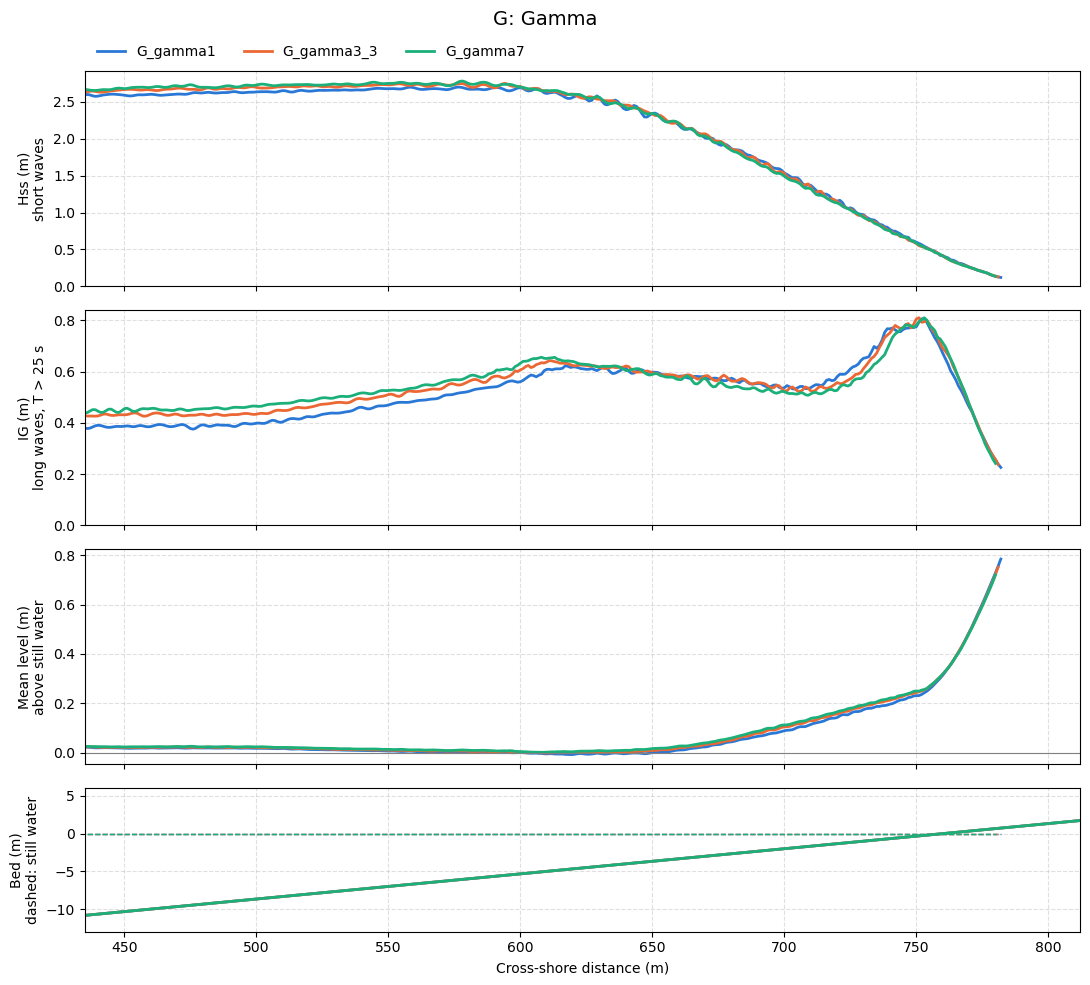

,G_gamma1,G_gamma3_3,G_gamma7
wave,jonswap,jonswap,jonswap
Hs (m),2.5,2.5,2.5
Tp (s),10.0,10.0,10.0
WL (m),0.0,0.0,0.0
Manning n,0.01,0.01,0.01
x_break (m),641.0,638.0,635.0
Hss/h at break,0.61,0.6,0.59
"Hss, h=1 m (m)",0.84,0.81,0.8
"IG, h=1 m (m)",0.7,0.71,0.66
IG/Hss,0.84,0.87,0.82


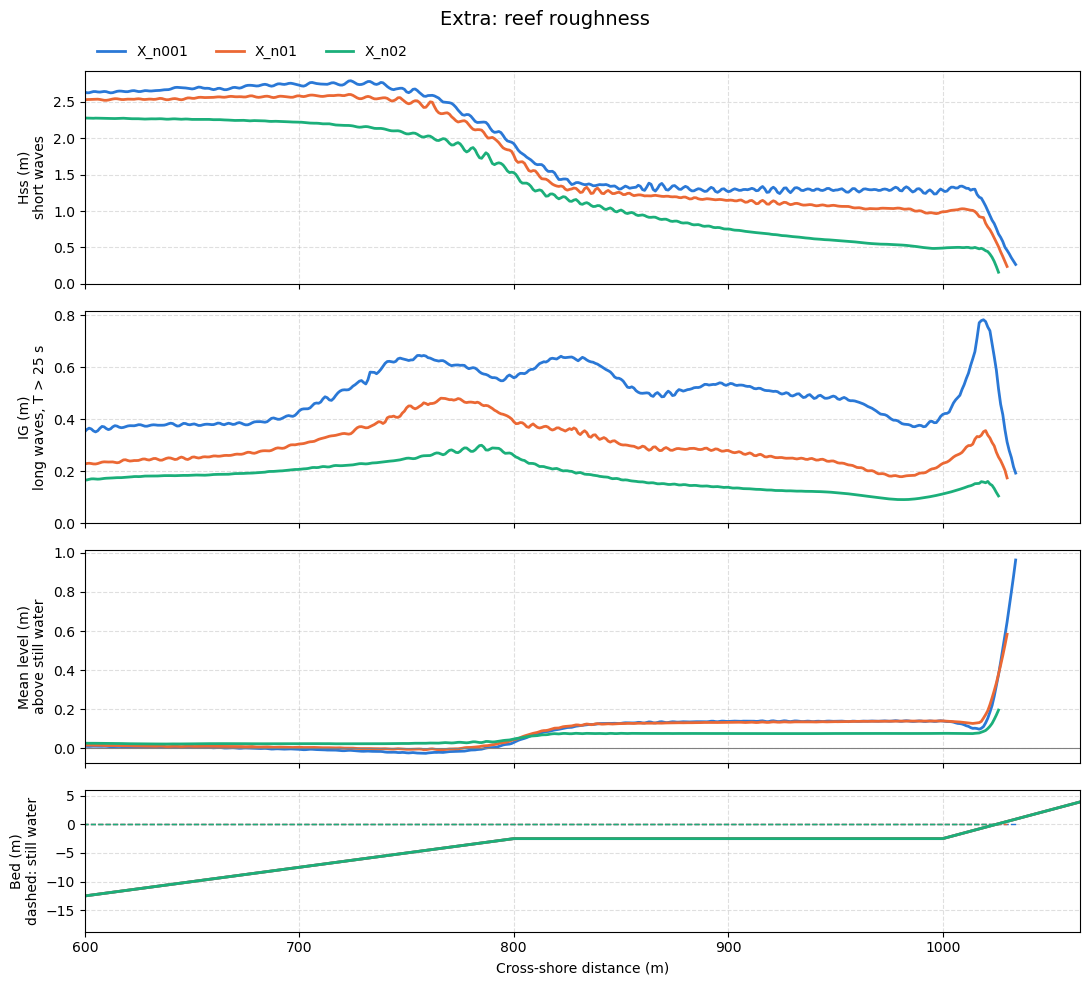

,X_n001,X_n01,X_n02
wave,jonswap,jonswap,jonswap
Hs (m),2.5,2.5,2.5
Tp (s),10.0,10.0,10.0
WL (m),0.0,0.0,0.0
Manning n,0.01,0.1,0.2
x_break (m),767.0,768.0,691.0
Hss/h at break,0.6,0.57,0.28
"Hss, h=1 m (m)",1.19,0.92,0.49
"IG, h=1 m (m)",0.77,0.33,0.15
IG/Hss,0.65,0.36,0.31


In [13]:
for group, cases in GROUPS.items():
    plot_results(list(cases), title=group)
    display(case_table(list(cases)))

## 5. Class table

Trend from the first case of each group to the last. Under 10% (10 m for x_break) counts as `=`.

In [14]:
trend_table({group: list(cases) for group, cases in GROUPS.items()})

,x_break (m),"Hss, h=1 m (m)","IG, h=1 m (m)",Setup at shore (m),Ru2 (m),Ru2 + WL (m)
A: irregular instead of regular,offshore (650 → 638),= (0.89 → 0.81),↑ (0.01 → 0.71),↓ (0.35 → 0.32),↑ (0.54 → 1.41),↑ (0.54 → 1.41)
B: Hs,offshore (698 → 580),↑ (0.70 → 0.89),↑ (0.24 → 1.27),↑ (0.14 → 0.51),↑ (0.79 → 1.94),↑ (0.79 → 1.94)
C: Tp,offshore (652 → 593),= (0.81 → 0.86),↑ (0.55 → 1.52),↑ (0.27 → 0.39),↑ (1.24 → 2.16),↑ (1.24 → 2.16)
D: beach slope,offshore (638 → 521),↑ (0.81 → 1.17),↓ (0.71 → 0.45),↑ (0.32 → 0.38),= (1.41 → 1.52),= (1.41 → 1.52)
E: bar height,offshore (638 → 619),↓ (0.81 → 0.65),↓ (0.71 → 0.45),↑ (0.32 → 0.38),↓ (1.41 → 1.23),↓ (1.41 → 1.23)
F: water level on the reef,onshore (749 → 788),↑ (0.77 → 1.55),↑ (0.61 → 0.89),↑ (0.29 → 0.40),↑ (1.34 → 2.19),↑ (0.34 → 3.19)
G: Gamma,= (641 → 635),= (0.84 → 0.80),= (0.70 → 0.66),= (0.31 → 0.32),= (1.47 → 1.36),= (1.47 → 1.36)
Extra: reef roughness,offshore (767 → 691),↓ (1.19 → 0.49),↓ (0.77 → 0.15),↓ (0.32 → 0.17),↓ (1.75 → 0.34),↓ (1.75 → 0.34)


## 6. Using a backup in class

If a group's run fails, show its result on the projector:

```python
plot_results(["B_Hs1", "B_Hs2_5", "B_Hs4"])
case_table(["B_Hs1", "B_Hs2_5", "B_Hs4"])
```

Or copy the case folders from `backup_results/` into `cases/` on the group's machine: then step 06 of their notebook finds them by name.

## 7. Save the backups to the solutions branch

```bash
git checkout solutions
git add backup_results
git commit -m "Backup runs"
git push
git checkout main
```